## Data Preprocessing

For Data Preprocessing, we use Scikit-Learn library.<br>
Installation command - **pip install scikit-learn**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('loan.csv')

In [3]:
df.head()

,loan_amnt,term,int_rate,installment,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,address
0,10000.0,36 months,11.44,329.48,Marketing,10+ years,RENT,117000.0,Not Verified,Jan-2015,Fully Paid,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,Credit analyst,4 years,MORTGAGE,65000.0,Not Verified,Jan-2015,Fully Paid,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,Statistician,< 1 year,RENT,43057.0,Source Verified,Jan-2015,Fully Paid,credit_card,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,Client Advocate,6 years,RENT,54000.0,Not Verified,Nov-2014,Fully Paid,credit_card,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,Destiny Management Inc.,9 years,MORTGAGE,55000.0,Verified,Apr-2013,Charged Off,credit_card,"679 Luna Roads\r\nGreggshire, VA 11650"


Taking starting 50000 rows for preprocessing

In [7]:
df = df.iloc[:50000,:]

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   loan_amnt            50000 non-null  float64
 1   term                 50000 non-null  object 
 2   int_rate             50000 non-null  float64
 3   installment          50000 non-null  float64
 4   emp_title            47144 non-null  object 
 5   emp_length           47708 non-null  object 
 6   home_ownership       50000 non-null  object 
 7   annual_inc           50000 non-null  float64
 8   verification_status  50000 non-null  object 
 9   issue_d              50000 non-null  object 
 10  loan_status          50000 non-null  object 
 11  purpose              50000 non-null  object 
 12  address              50000 non-null  object 
dtypes: float64(4), object(9)
memory usage: 5.0+ MB


In [10]:
df.columns

Index(['loan_amnt', 'term', 'int_rate', 'installment', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'purpose', 'address'],
      dtype='object')

### 1. Checking For Duplicates

In [14]:
df.duplicated().sum()

0

### 2. Missing Values Detection

In [15]:
df.isna().sum()

loan_amnt                 0
term                      0
int_rate                  0
installment               0
emp_title              2856
emp_length             2292
home_ownership            0
annual_inc                0
verification_status       0
issue_d                   0
loan_status               0
purpose                   0
address                   0
dtype: int64

### 3. Outlier Detection

- Outliers can be detected only in numerical columns
- It is not possible to have outliers in categorical columns

In [23]:
df_numeric = df.select_dtypes(include=['float','int'])
df_numeric.head(3)

,loan_amnt,int_rate,installment,annual_inc
0,10000.0,11.44,329.48,117000.0
1,8000.0,11.99,265.68,65000.0
2,15600.0,10.49,506.97,43057.0


In [24]:
df_categorical = df.select_dtypes(include = 'object')
df_categorical.head(3)

,term,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,purpose,address
0,36 months,Marketing,10+ years,RENT,Not Verified,Jan-2015,Fully Paid,vacation,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,36 months,Credit analyst,4 years,MORTGAGE,Not Verified,Jan-2015,Fully Paid,debt_consolidation,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,36 months,Statistician,< 1 year,RENT,Source Verified,Jan-2015,Fully Paid,credit_card,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"


Outliers can be detected using two different plots
1.  Box Plot
2.  Density Plot

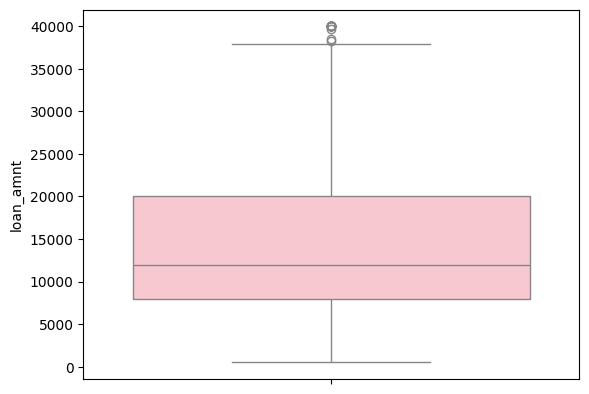

In [30]:
# Loan Amount Column -
sns.boxplot(y=df['loan_amnt'], color='pink')
plt.show()

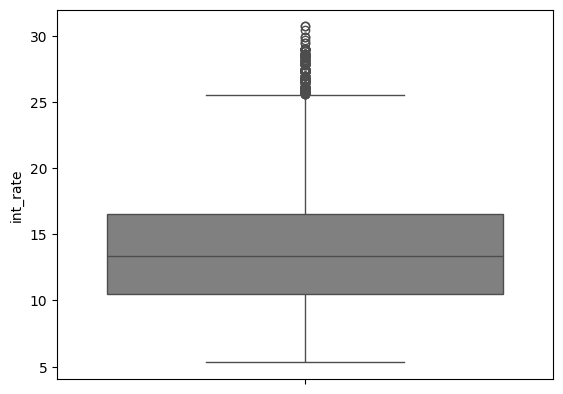

In [31]:
# Interest Rate Column - 
sns.boxplot(y=df['int_rate'], color='grey')
plt.show()

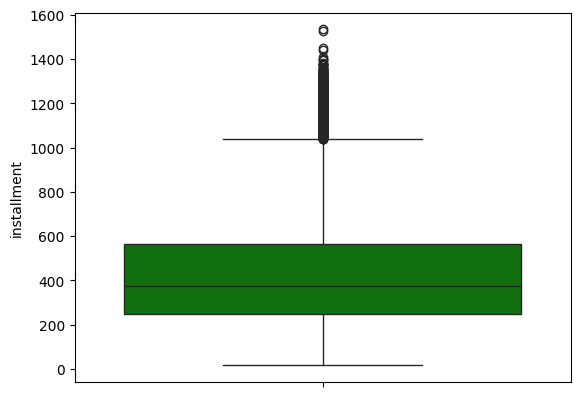

In [32]:
# Installment Column -
sns.boxplot(y=df['installment'], color='green')
plt.show()

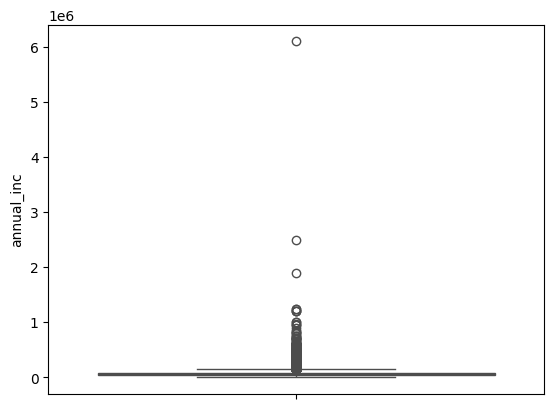

In [33]:
# Annual Income Column -
sns.boxplot(y=df['annual_inc'], color='blue')
plt.show()

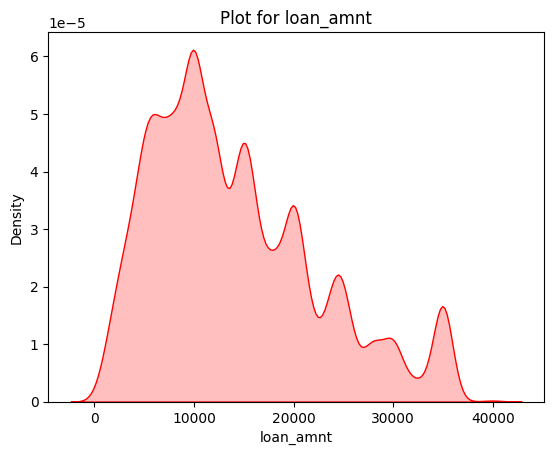

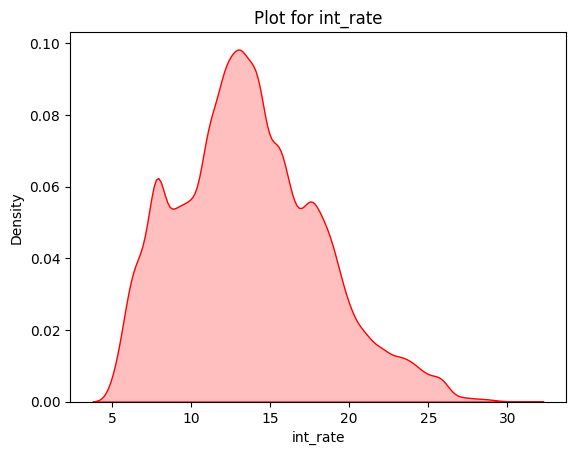

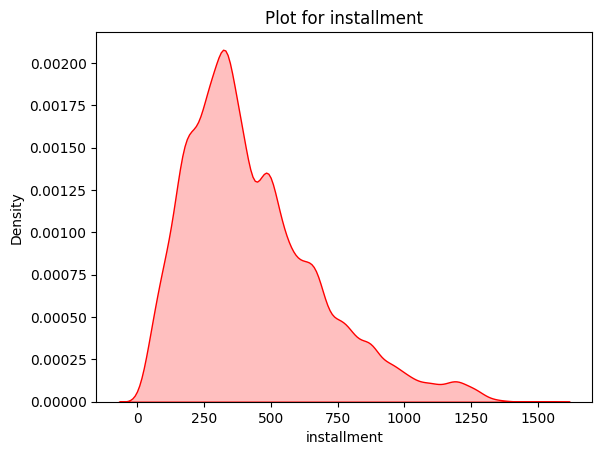

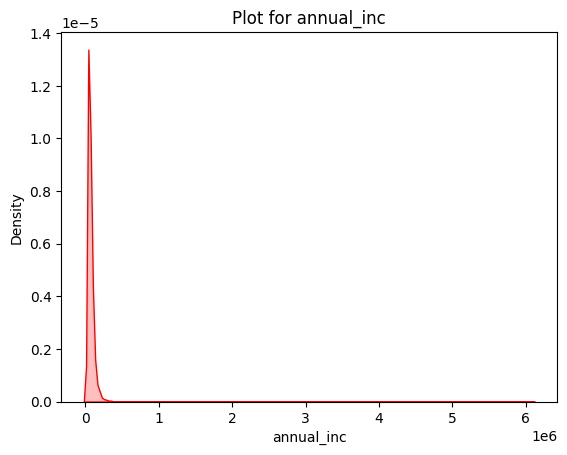

In [46]:
for col in df_numeric.columns:
    sns.kdeplot(x=df[col], fill=True, color='red')
    plt.title(f'Plot for {col}')
    plt.show()

#### Displaying the statistical summary of the numeric columns

In [47]:
df_numeric.describe()

,loan_amnt,int_rate,installment,annual_inc
count,50000.000000,50000.000000,50000.000000,5.000000e+04
mean,14105.965000,13.657471,431.434680,7.417736e+04
std,8361.115955,4.461604,250.253421,5.767275e+04
min,500.000000,5.320000,16.310000,2.500000e+03
25%,8000.000000,10.490000,250.367500,4.500000e+04
50%,12000.000000,13.330000,375.490000,6.350000e+04
75%,20000.000000,16.550000,566.225000,9.000000e+04
max,40000.000000,30.740000,1533.810000,6.100000e+06


#### Observation:
- A big difference in the maximum value and 75th percentile is seen inside the Installment & Annual Income Column
- Hence we can treat its outliers with the help of IQR method.
- IQR gives us the row numbers having outliers.

### 4. Data Distributions

**A. Categorical Columns**

In [48]:
df_categorical.columns

Index(['term', 'emp_title', 'emp_length', 'home_ownership',
       'verification_status', 'issue_d', 'loan_status', 'purpose', 'address'],
      dtype='object')

In [51]:
for col in df_categorical.columns:
    print(f'{col} - {df[col].nunique()}')

term - 2
emp_title - 28999
emp_length - 11
home_ownership - 6
verification_status - 3
issue_d - 115
loan_status - 2
purpose - 14
address - 49954


Checking the distribution of some selected columns having less number of unique values

C:\Users\Maisara Waseem\AppData\Local\Temp\ipykernel_19232\2236312959.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:purple'` for the same effect.

  sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')


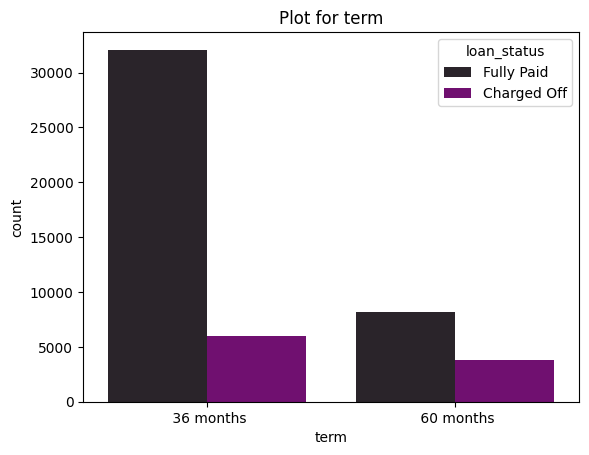

C:\Users\Maisara Waseem\AppData\Local\Temp\ipykernel_19232\2236312959.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:purple'` for the same effect.

  sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')


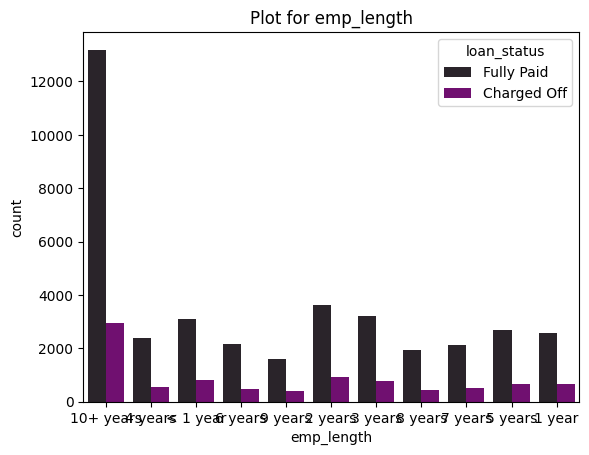

C:\Users\Maisara Waseem\AppData\Local\Temp\ipykernel_19232\2236312959.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:purple'` for the same effect.

  sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')


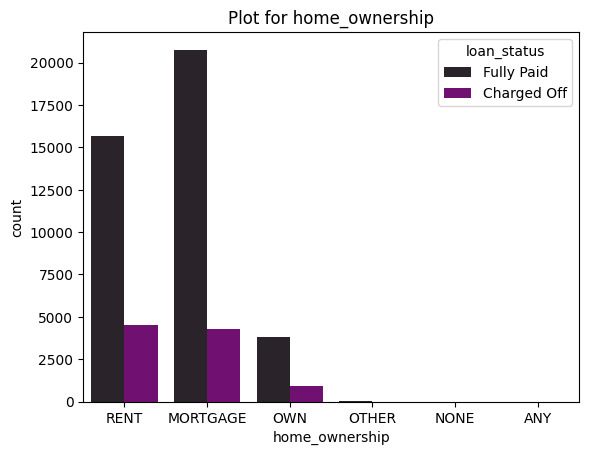

C:\Users\Maisara Waseem\AppData\Local\Temp\ipykernel_19232\2236312959.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:purple'` for the same effect.

  sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')


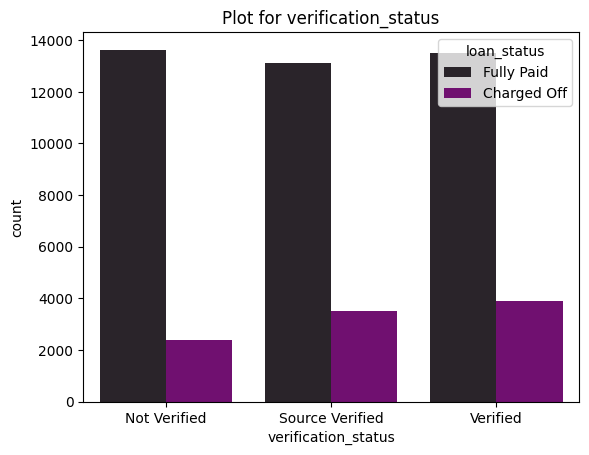

In [55]:
for c in ['term', 'emp_length', 'home_ownership', 'verification_status']:
    sns.countplot(x=c, data=df_categorical, color='purple', hue='loan_status')
    plt.title(f'Plot for {c}')
    plt.show()

**B. Numeric Columns**

In [24]:
df_numeric.columns

Index(['loan_amnt', 'int_rate', 'installment', 'annual_inc'], dtype='object')

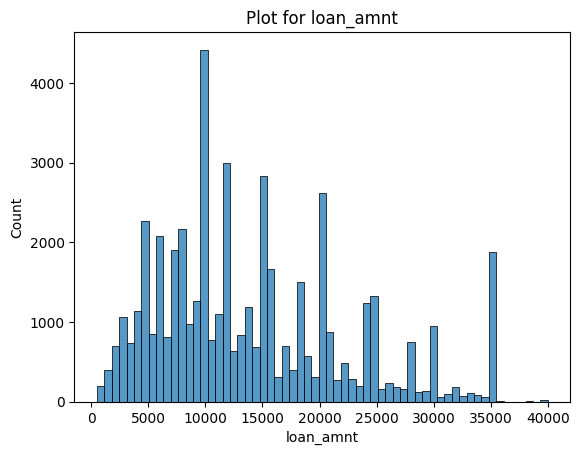

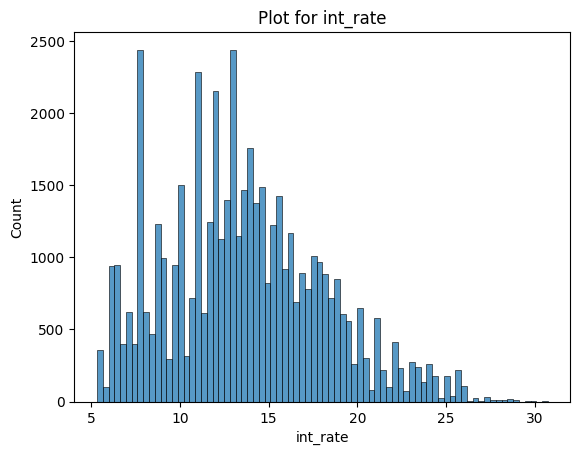

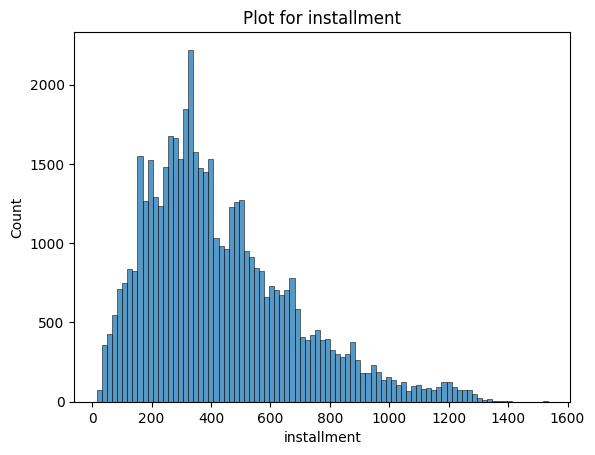

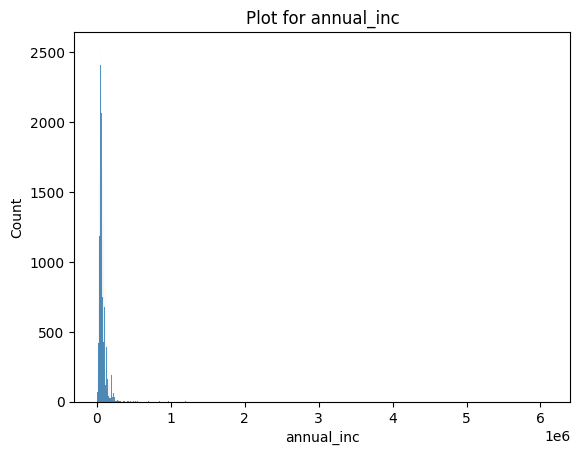

In [57]:
for c in df_numeric.columns:
    sns.histplot(x=c, data=df_numeric)
    plt.title(f'Plot for {c}')
    plt.show()